In [1]:
import sys
sys.path.append('/nfs/dataset-ofs-385-143496/yangliu/lite-fea-workspace/wh/demo/thirdparty/copersona/')
from copersona.utils import dmpax, tools


app_name = "home_company_fix56790993302"
spark2conf = {
    "master": "yarn",
    "spark.submit.deployMode": "client",
    "driver-memory": "4g",
    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "40",
    "spark.dynamicAllocation.maxExecutors": "60",
    "spark.executor.cores": "4",
    "spark.executor.memory": "6g",
    "spark.default.parallelism": "1000",
    "spark.sql.shuffle.partitions": "1000",
    "spark.yarn.queue": "root.profile_prod",
    "spark.sql.autoBroadcastJoinThreshold": "-1",
    "spark.sql.broadcastTimeout": "3000",
    "spark.driver.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.executor.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.yarn.dist.archives": "hdfs://difed/user/dm/ENV/dlflow/1.0.1/py3.7.5_for_tfcluster.tgz",
    "spark.executorEnv.PYSPARK_PYTHON": "./py3.7.5_for_tfcluster.tgz/py3.7.5_for_tfcluster/bin/python3",
    "spark.jars": (
        "hdfs://difed/user/dm/ENV/jars/spark_jars/xgboost4j-0.90.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/xgboost4j-spark-0.90.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/spark-tensorflow-connector_2.11-1.14.0.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/tensorflow-hadoop-1.14.0.jar,"
        "hdfs://difed/user/dm/ENV/jars/spark_jars/spark-tfrecord_2.11-0.2.3.jar"
    ),
    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",
    "spark.driver.extraClassPath": "/opt/miniconda3/lib/python3.7/site-packages/sparkmonitor/listener_2.11.jar"
}


TF211_PY_ENV="hdfs://difed/user/dm/ENV/dlflow/v2/py3.7.15_for_tfcluster.tgz"
TF211_PY_BIN="./py3.7.15_for_tfcluster.tgz/py3.7.15_for_tfcluster/bin/python3"

TF283_PY_ENV="hdfs://difed/user/dm/ENV/zhouyc/tf2.8.3.tgz"
TF283_PY_BIN="./tf2.8.3.tgz/bin/python3"

spark3conf = {
    "master": "yarn",
    "spark.submit.deployMode": "client",
    "driver-memory": "4g",
    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "10",
    "spark.dynamicAllocation.maxExecutors": "100",
    "spark.executor.cores": "4",
    "spark.executor.memory": "6g",
    "spark.executor.memoryOverhead":"10g",
    "spark.sql.hive.manageFilesourcePartitions":"false",
    "spark.default.parallelism": "200",
    "spark.sql.shuffle.partitions": "200",
    "spark.yarn.queue": "root.profile_prod",
    "spark.sql.autoBroadcastJoinThreshold": "-1",
    "spark.sql.broadcastTimeout": "3000",
    "spark.driver.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.executor.extraJavaOptions": "-Dcom.github.fommil.netlib.BLAS=com.github.fommil.netlib.F2jBLAS",
    "spark.yarn.dist.archives": "",
    "spark.executorEnv.PYSPARK_PYTHON": "",
    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",
    "spark.driver.extraClassPath": "/opt/miniconda3/lib/python3.7/site-packages/sparkmonitor/listener_2.12.jar",
    
    
    "spark.jars": (
        "hdfs://difed/user/dm/ENV/jars/spark_tfrecord/compile/spark-tfrecord-0.5.1_scala2.12-spark3.2.0-tfhp1.15.0.jar"
    ),   
}

spark3conf['spark.executorEnv.PYSPARK_PYTHON'] = TF211_PY_BIN
spark3conf['spark.yarn.dist.archives'] = TF211_PY_ENV

spark_app = dmpax.SparkBaseApp()
spark_app.initialize(app_name, spark3conf)
spark = spark_app.spark
hdfs = spark_app.hdfs

print("[Info] Spark Version : {}".format(spark.version))

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
Application Id: application_1774879587659_26183422, Tracking URL: http://bigdata-nmg-hdprm00.nmg01:8088/proxy/application_1774879587659_26183422/
INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 51144)
INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 51144)


[Info] Spark Version : 3.2.0-101


In [2]:
import warnings
warnings.filterwarnings("ignore")

import pyspark
import os
import json
import math
import sys
import random
import importlib
import seaborn as sns
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt


import pyspark.sql.types as T
from pyspark.files import SparkFiles
from pyspark.sql   import functions as func
from pyspark.sql   import DataFrame
from pyspark.sql.window import Window
from tqdm import tqdm
from functools import reduce



from ortools.linear_solver import pywraplp
from sklearn.metrics import roc_auc_score


sys.path.append('/nfs/dataset-ofs-385-143496/yangliu/lite-fea-workspace/wh/demo/thirdparty/backflow/')

from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats   as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools
import datetime,json
import pandas as pd

from pyspark.sql.functions import col,desc, udf
from pyspark.sql.types import StructType
from pyspark.sql.types import StructField
from pyspark.sql.types import StringType
from pyspark.sql import DataFrame
from pyspark.sql import functions as func


importlib.reload(exp_setting)
importlib.reload(pgt)
importlib.reload(calib_metric)
importlib.reload(calib_stats)
importlib.reload(vis)
importlib.reload(pgtsimu)
importlib.reload(bkfl_tools)


pd.set_option('display.max_columns', None)

load metric func from causalml...
load metric func from causalml...


In [4]:
if True:
    import warnings
    warnings.filterwarnings("ignore")

    import pyspark
    import os
    import json
    import math
    import sys
    import random
    import importlib
    import seaborn as sns
    import numpy as np
    import pandas as pd
    import itertools
    import matplotlib.pyplot as plt
    import matplotlib.pyplot as plt


    import pyspark.sql.types as T
    from pyspark.files import SparkFiles
    from pyspark.sql   import functions as func
    from pyspark.sql   import DataFrame
    from pyspark.sql.window import Window
    from tqdm import tqdm
    from functools import reduce

    from sklearn.metrics import roc_auc_score

    import datetime,json
    import pandas as pd

    from pyspark.sql.functions import col,desc, udf
    from pyspark.sql.types import StructType
    from pyspark.sql.types import StructField
    from pyspark.sql.types import StringType
    from pyspark.sql import DataFrame
    from pyspark.sql import functions as func

    

    pd.set_option('display.max_columns', None)

In [5]:
#pv维度的auc
def caculate_auc(y_labels,y_scores):
    label_unique=list(set(y_labels))
    label_unique.sort(reverse=True)

    # print("label 种类：")
    # print(label_unique)
    f = list(zip(y_scores, y_labels))
    rank = [values2 for values1, values2 in sorted(f, key=lambda x:x[0])]
    cnt=0
    for label in label_unique:
        if label==0:
            continue
        label_dict={}
        for item in label_unique:
            label_dict[item]=0
        #rank根据打分从小到大排序，for循环从小到大遍历到当前标签时，计算前面打分小的label中真正比当前label小的个数
        for i in range(len(rank)):
            if rank[i]==label:
                for item in label_unique:
                    if item<label:
                        cnt+=label_dict[item]

            label_dict[rank[i]]+=1
    label_dict={}
    for item in y_labels:
        if item not in label_dict:
            label_dict[item]=0
        label_dict[item]+=1
    total_len=0
    label_num=len(y_labels)
    for i in range(len(label_unique)-1):
        total_len=total_len+label_dict[label_unique[i]]*(label_num-label_dict[label_unique[i]])
        # print(total_len)
        label_num=label_num-label_dict[label_unique[i]]

    return cnt/total_len

## euen_base

In [ ]:
# 把真实实验数据和训练后生成预测的hive落表拼接起来

In [ ]:
QUERY_ALL_FMT = """
with base as (
    select t1.*
    from
    ( select
       if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid, oneid,
        flowtree_group_name,
        send_cnt, send_success_cnt, send_cost, send_remind_cost, outcall_cost, remind_cost, msg_coupon_cost as coupon_cost,outcall_coupon_cost,outcall_coupon2_cost, 
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost, 0.0)+ nvl(outcall_coupon_cost, 0.0)+ nvl(outcall_coupon2_cost, 0.0)) as double) as cost,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d,
        dt,  if(fin_order_mini_28d >= 3, 1, 0.72) as weight, 
        if(fin_order_mini_28d >= 3, 1, 0) as fin_order_mini_28d
    from {traindata_tbname_via_growstrategy}
    where dt in {seed_dts}
    and new_exp = '迭代流量'
    and fin_order_mini_28d >= 3
    and ((flowtree_group_name = '探索' and group_name_eve in ('555', '5折5折5折(cap10)','留存6张3元', '留存6张5元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
    )t1
),
prediction_agg as (
    select
        bs.*,
        nvl(mapping_data.uplift_1,999) as euen_v213_uplift_cost_010203_uplift_1,
        nvl(mapping_data.uplift_4,999) as euen_v213_uplift_cost_010203_uplift_4,
        nvl(mapping_data.uplift_5,999) as euen_v213_uplift_cost_010203_uplift_5,
        nvl(mapping_data.uplift_6,999) as euen_v213_uplift_cost_010203_uplift_6,
        nvl(mapping_data.cost_1,999) as euen_v213_uplift_cost_010203_cost_1,
        nvl(mapping_data.cost_4,999) as euen_v213_uplift_cost_010203_cost_4,
        nvl(mapping_data.cost_5,999) as euen_v213_uplift_cost_010203_cost_5,
        nvl(mapping_data.cost_6,999) as euen_v213_uplift_cost_010203_cost_6
    from (
        select * from base
    ) bs
    left join (
        select 
            pid,
            label_dt as dt,
            uplift_1,
            uplift_4, 
            uplift_5,
            uplift_6,
            cost_1,
            cost_4, 
            cost_5, 
            cost_6
        from {mapping_data}
        where label_dt in {seed_dts}  
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt 
)

select *
from prediction_agg
"""

all_rct_data_fmt = QUERY_ALL_FMT.format(
    seed_dts=tuple(dt for dt in CHECK_DTS[1:]),
    dts=tuple(dt for dt in CHECK_DTS[:]),
    traindata_tbname_via_growstrategy='growstrategy.ut_alg_flowback_msg_label_v2_di',
    mapping_data='growstrategy.ut_mkt_backflow_multi_treat_eeuen_v111_uplift_cost_4_5_06_model_inference_di'
)
all_rct_data_df = spark.sql(all_rct_data_fmt)
v117 = all_rct_data_df.toPandas()


In [25]:
import pandas as pd

# 1. 过滤未匹配到的异常值
cols_to_check = [
    'left63', 'left65', 'left853', 
    'left65_minus_left63', 'left853_minus_left63', 
    'cost_1', 'cost_2', 'cost_3'
]
valid_mask = ~BASE_FMT_v1[cols_to_check].isin([999]).any(axis=1)
df_valid = BASE_FMT_v1[valid_mask]
total_samples = len(df_valid)

# 2. 独立定义三个条件

# 条件 A: 只看 CVR/增效倒挂 (绝对值倒挂 + 增量倒挂)
cond_cvr = (df_valid['left63'] >= 0) & \
           (df_valid['left853'] > df_valid['left63']) & \
           (df_valid['left65'] > df_valid['left853'])

# 条件 B: 只看 Cost 递增 (8元 > 5元 > 3元)
cond_cost = (df_valid['cost_1'] >= 0) & \
            (df_valid['cost_2'] > df_valid['cost_1']) & \
            (df_valid['cost_3'] > df_valid['cost_2'])

# 条件 C: 两者同时满足 (交集)
cond_both = cond_cvr & cond_cost

# 3. 计算并打印分析报告
print("========== 深入拆解：CVR 与 Cost 满足比例 ==========\n")
print(f"底座总有效样本数 : {total_samples:,} 条\n")

# --- 切面 1: 只看 CVR ---
cvr_count = cond_cvr.sum()
print(f"【1. 只看 CVR (增效倒挂)】")
print(f"   - 满足条数: {cvr_count:,}")
print(f"   - 不满足条数: {total_samples - cvr_count:,}")
print(f"   => 满足比例: {cvr_count / total_samples:.2%}\n")

# --- 切面 2: 只看 Cost ---
cost_count = cond_cost.sum()
print(f"【2. 只看 Cost (成本正常递增)】")
print(f"   - 满足条数: {cost_count:,}")
print(f"   - 不满足条数: {total_samples - cost_count:,}")
print(f"   => 满足比例: {cost_count / total_samples:.2%}\n")

# --- 切面 3: 两者交集 ---
both_count = cond_both.sum()
print(f"【3. 两者都要满足 (最终交集)】")
print(f"   - 满足条数: {both_count:,}")
print(f"   - 不满足条数: {total_samples - both_count:,}")
print(f"   => 满足比例: {both_count / total_samples:.2%}")
print("==================================================")

========== 深入拆解：CVR 与 Cost 满足比例 ==========

底座总有效样本数 : 618,970 条

【1. 只看 CVR (增效倒挂)】
   - 满足条数: 608,511
   - 不满足条数: 10,459
   => 满足比例: 98.31%

【2. 只看 Cost (成本正常递增)】
   - 满足条数: 616,483
   - 不满足条数: 2,487
   => 满足比例: 99.60%

【3. 两者都要满足 (最终交集)】
   - 满足条数: 606,099
   - 不满足条数: 12,871
   => 满足比例: 97.92%


In [27]:
import pandas as pd

# 1. 过滤未匹配到的异常值
cols_to_check = [
    'left63', 'left65', 'left853', 
    'left65_minus_left63', 'left853_minus_left63', 
    'cost_1', 'cost_2', 'cost_3'
]
valid_mask = ~BASE_FMT_v4[cols_to_check].isin([999]).any(axis=1)
df_valid = BASE_FMT_v4[valid_mask]
total_samples = len(df_valid)

# 2. 独立定义三个条件

# 条件 A: 只看 CVR/增效倒挂 (绝对值倒挂 + 增量倒挂)
cond_cvr = (df_valid['left63'] >= 0) & \
           (df_valid['left853'] > df_valid['left63']) & \
           (df_valid['left65'] > df_valid['left853'])

# 条件 B: 只看 Cost 递增 
cond_cost = (df_valid['cost_1'] >= 0) & \
            (df_valid['cost_2'] > df_valid['cost_1']) & \
            (df_valid['cost_3'] > df_valid['cost_2'])

# 条件 C: 两者同时满足 (交集)
cond_both = cond_cvr & cond_cost

# 3. 计算并打印分析报告
print("========== 深入拆解：CVR 与 Cost 满足比例 ==========\n")
print(f"底座总有效样本数 : {total_samples:,} 条\n")

# --- 切面 1: 只看 CVR ---
cvr_count = cond_cvr.sum()
print(f"【1. 只看 CVR (增效倒挂)】")
print(f"   - 满足条数: {cvr_count:,}")
print(f"   - 不满足条数: {total_samples - cvr_count:,}")
print(f"   => 满足比例: {cvr_count / total_samples:.2%}\n")

# --- 切面 2: 只看 Cost ---
cost_count = cond_cost.sum()
print(f"【2. 只看 Cost (成本正常递增)】")
print(f"   - 满足条数: {cost_count:,}")
print(f"   - 不满足条数: {total_samples - cost_count:,}")
print(f"   => 满足比例: {cost_count / total_samples:.2%}\n")

# --- 切面 3: 两者交集 ---
both_count = cond_both.sum()
print(f"【3. 两者都要满足 (最终交集)】")
print(f"   - 满足条数: {both_count:,}")
print(f"   - 不满足条数: {total_samples - both_count:,}")
print(f"   => 满足比例: {both_count / total_samples:.2%}")
print("==================================================")

========== 深入拆解：CVR 与 Cost 满足比例 ==========

底座总有效样本数 : 618,970 条

【1. 只看 CVR (增效倒挂)】
   - 满足条数: 616,234
   - 不满足条数: 2,736
   => 满足比例: 99.56%

【2. 只看 Cost (成本正常递增)】
   - 满足条数: 611,125
   - 不满足条数: 7,845
   => 满足比例: 98.73%

【3. 两者都要满足 (最终交集)】
   - 满足条数: 608,459
   - 不满足条数: 10,511
   => 满足比例: 98.30%


In [32]:
import pandas as pd

# 1. 过滤未匹配到的异常值
cols_to_check = [
    'left63', 'left65', 'left853', 
    'left65_minus_left63', 'left853_minus_left63'
]
valid_mask = ~BASE_FMT_v2[cols_to_check].isin([999]).any(axis=1)
df_valid = BASE_FMT_v2[valid_mask]
total_samples = len(df_valid)

# 2. 独立定义三个条件

# 条件 A: 只看 CVR/增效倒挂 (绝对值倒挂 + 增量倒挂)
cond_cvr = (df_valid['left63'] >= 0) & \
           (df_valid['left853'] > df_valid['left63']) & \
           (df_valid['left65'] > df_valid['left853'])




# 3. 计算并打印分析报告
print("========== 深入拆解：CVR 与 Cost 满足比例 ==========\n")
print(f"底座总有效样本数 : {total_samples:,} 条\n")

# --- 切面 1: 只看 CVR ---
cvr_count = cond_cvr.sum()
print(f"【1. 只看 CVR (增效倒挂)】")
print(f"   - 满足条数: {cvr_count:,}")
print(f"   - 不满足条数: {total_samples - cvr_count:,}")
print(f"   => 满足比例: {cvr_count / total_samples:.2%}\n")



========== 深入拆解：CVR 与 Cost 满足比例 ==========

底座总有效样本数 : 618,792 条

【1. 只看 CVR (增效倒挂)】
   - 满足条数: 281,139
   - 不满足条数: 337,653
   => 满足比例: 45.43%



In [6]:
BASE_FMT_v1 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(remind_cost, 0.0) + nvl(msg_coupon_cost, 0.0)) as double) as cost
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-05-06' and '2026-05-11'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '8元留存5张3', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select 
        bs.*,
        case when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        mapping_data.treatment as model_treatment,
        

        mapping_data.left65_minus_left63,
        mapping_data.left853_minus_left63,
        mapping_data.left63,


        (nvl(mapping_data.left63, 0.0) + nvl(mapping_data.left65_minus_left63, 0.0)) as left65,
        (nvl(mapping_data.left63, 0.0) + nvl(mapping_data.left853_minus_left63, 0.0)) as left853,
        
        mapping_data.cost_1,
        mapping_data.cost_2,
        mapping_data.cost_3
    from base bs
    join (
       select 
            pid,
            date_add(label_dt, 1) as dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853_minus_left63,
            uplift_3 as left65_minus_left63,
            cost_1,
            cost_2,
            cost_3
        from growstrategy.ut_mkt_backflow_multi_treat_euen_v216_xnetwork12_new_uplift_epoch2_1_model_inference_di



        where label_dt between '2026-05-05' and '2026-05-10' 
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)
select *
from prediction_agg
""").toPandas()

BASE_FMT_v1.head(25)

    

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost,real_treatment,model_treatment,left65_minus_left63,left853_minus_left63,left63,left65,left853,cost_1,cost_2,cost_3
0,迭代流量,DS空白,DS空白,control_group,100014829,v1_26a9143e68257244dc387b13d91b6619,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-05-08,0.0,0.0,0,0.0,0.023999,0.015699,0.012423,0.036421,0.028122,0.019794,0.035109,0.038431
1,迭代流量,探索,探索,留存6张3元,100178357,v1_17592930716160,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-05-09,0.0,0.0,1,1.0,0.008948,0.006234,0.003852,0.012799,0.010086,0.006944,0.010541,0.013901
2,迭代流量,探索,探索,留存6张3元,1002395537409,v1_d1c55e6e467557d482534f46d84d3edf,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-05-08,0.0,0.0,1,1.0,0.010673,0.008211,0.005464,0.016137,0.013675,0.010794,0.017854,0.019811
3,迭代流量,DS空白,DS空白,control_group,100418735,v1_17592940307532,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-08,0.0,0.0,0,0.0,0.055043,0.038207,0.027995,0.083037,0.066202,0.036992,0.092091,0.098646
4,迭代流量,DS空白,DS空白,control_group,10071213,v1_17592915714028,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28.0,2026-05-09,0.0,0.0,0,0.0,0.008728,0.006012,0.003432,0.012161,0.009444,0.005117,0.009495,0.012387
5,迭代流量,探索,探索,8元留存5张3,100715548,v1_1bad91f7e0caf789293505b3e100b36a,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-09,0.0,0.0,2,2.0,0.033117,0.021297,0.017278,0.050394,0.038575,0.028370,0.050180,0.054212
6,迭代流量,DS空白,DS空白,control_group,100826357762,v1_17592720927599,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27.0,2026-05-06,0.0,0.0,0,0.0,0.009320,0.006614,0.003664,0.012983,0.010278,0.004249,0.008978,0.012593
7,迭代流量,DS空白,DS空白,control_group,100840611,v1_17592916244418,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.0,2026-05-11,0.0,0.0,0,0.0,0.006455,0.004605,0.002391,0.008846,0.006996,0.002171,0.006037,0.007374
8,迭代流量,探索,探索,8元留存5张3,100846639,v1_17592424699315,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-05-06,0.0,0.0,2,2.0,0.013200,0.007959,0.005922,0.019122,0.013882,0.009468,0.016152,0.018939
9,迭代流量,DS空白,DS空白,control_group,1010178523137,v1_17592419798240,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,2026-05-11,0.0,0.0,0,0.0,0.009760,0.006687,0.003782,0.013542,0.010469,0.006093,0.010006,0.013564


In [ ]:
left6_df = cost_7d_df[cost_7d_df['group_name_eve']=='留存6张3元']   # 6
caculate_auc(left6_df['cost_7d'], left6_df['coupon_prob'])

left65_minus_left63    0.923589
Random                 0.476501
dtype: float64
****************************************


[left65_minus_left63    0.923589
 Random                 0.476501
 dtype: float64]

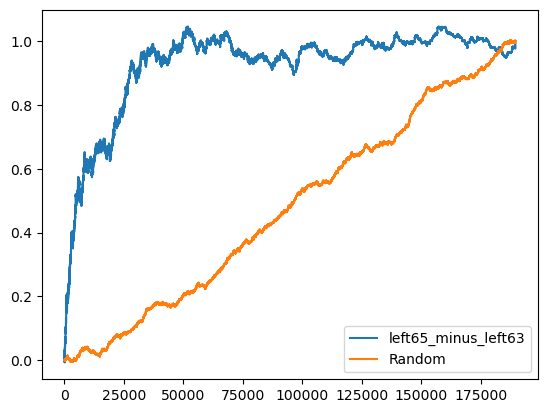

In [38]:
vis.draw_auuc(BASE_FMT_v1,
              treatments=[3], 
              ite_names=['left65_minus_left63'], 
              label_col='label',  
              curve_type='auuc',
              real_treatment='real_treatment', 
              control_group_name=1, # 注意这里是用中括号包起来的
              show_curve=1
        )

In [ ]:
vis.draw_auuc(BASE_FMT_v1,
              treatments=[2], 
              ite_names=['left853_minus_left63'], 
              label_col='label',  
              curve_type='auuc',
              real_treatment='real_treatment', 
              control_group_name=1, # 确保两个都是长度为 1 的列表
              show_curve=1
        )

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v1,
              treatments=[1], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [42]:
left6_df =  BASE_FMT_v2 [BASE_FMT_v2['group_name_eve']=='留存6张3元']   # 1
caculate_auc(left6_df['cost'], left6_df['coupon_prob'])

0.5255208390612732

## 因果森林

In [41]:
BASE_FMT_v2 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(remind_cost, 0.0) + nvl(msg_coupon_cost, 0.0)) as double) as cost
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-05-06' and '2026-05-11'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '8元留存5张3', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select 
        bs.*,
        
        -- 1. 生成真实对照组标签
        case when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        mapping_data2.coupon_prob,
        
        -- 2. 解析预测打分
        mapping_data.left63,
        mapping_data.left853,
        mapping_data.left65,
        
        -- 3. 直接做差，生成排序依据
        case 
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left63
        end as left65_minus_left63,
        
        case 
            when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left853 - mapping_data.left63
        end as left853_minus_left63
       
    from base bs
    left join (
       select 
            pid as oneid,         
            date_add(dt, 1) as join_dt,
            prediction[0] as left63,
            prediction[1] as left853,
            prediction[2] as left65
        from dm.ut_mkt_backflow_model_inference_di
        where dt between '2026-05-05' and '2026-05-10'
        and model = 'bkfl_multi_treatment_26_v2_uplift'
    ) mapping_data 
        on bs.oneid = mapping_data.oneid 
        and bs.dt = mapping_data.join_dt      
    left join (
        select 
            pid as oneid
            ,date_add(dt, 1) as dt
            ,weighted_prob as coupon_prob
        from dm.ut_mkt_backflow_model_inference_di
        where dt between '2026-05-05' and '2026-05-10'
        and model = 'bkfl_group_to_coupon_26_v2'
    ) mapping_data2 on bs.oneid = mapping_data2.oneid and bs.dt = mapping_data2.dt
)
select *
from prediction_agg
""").toPandas()
BASE_FMT_v2.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost,real_treatment,coupon_prob,left63,left853,left65,left65_minus_left63,left853_minus_left63
0,迭代流量,探索,探索,8元留存5张3,17592270785279,v1_0014f3f790998d0b9d5e5d4f7263c277,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-05-10,0.0,0.0,2,0.002440,0.012194,0.013740,0.015237,0.003043,0.001546
1,迭代流量,探索,探索,留存6张3元,17594549546572,v1_002778b54d99d4ed73429f087dd63450,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,2026-05-07,0.0,0.0,1,0.015239,0.004366,0.007841,0.009217,0.004851,0.003475
2,迭代流量,探索,探索,留存6张5元,17595261398173,v1_003e77355a6ef1b4237852c1866c881e,2.0,1.0,0.021,0.000,1.0,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0,2026-05-07,0.0,0.0,3,0.015807,0.005438,0.007257,0.006307,0.000869,0.001819
3,迭代流量,DS空白,DS空白,control_group,17597846115501,v1_006af0325e5f56044b957ca034b2a4e6,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-10,0.0,0.0,0,0.010882,0.031487,0.057032,0.043331,0.011844,0.025544
4,迭代流量,DS空白,DS空白,control_group,17592537754869,v1_0096af30c91b975c8d5e3a1a60453ef4,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-05-10,0.0,0.0,0,0.003551,0.010266,0.010654,0.015783,0.005516,0.000387
5,迭代流量,DS空白,DS空白,control_group,2256543678581,v1_00a6ae3cb99d9b153c6d56b05bbf4c7f,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,2026-05-09,0.0,0.0,0,0.007315,0.011120,0.017141,0.012792,0.001672,0.006020
6,迭代流量,DS空白,DS空白,control_group,17599230165283,v1_00a956a77f8036b4d403b20fdd664b5b,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.0,2026-05-06,0.0,0.0,0,0.006539,0.008610,0.010465,0.011164,0.002554,0.001855
7,迭代流量,探索,探索,留存6张5元,2348196504611,v1_00bca6f5521f1f88da69e66dd12ed9a1,2.0,1.0,0.021,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,2026-05-11,0.0,0.0,3,0.087591,0.018191,0.017318,0.020659,0.002468,-0.000873
8,迭代流量,DS空白,DS空白,control_group,17594753826574,v1_0113ceac3abbabebf207b1c513e7391f,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.0,2026-05-11,0.0,0.0,0,0.085526,0.005604,0.005596,0.006024,0.000419,-0.000008
9,迭代流量,探索,探索,留存6张3元,35185596352034,v1_013ce807740849f3d63f6abbbfef498e,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-05-08,0.0,0.0,1,0.021002,0.025750,0.032531,0.032196,0.006446,0.006781


In [28]:
BASE_FMT_v2 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(remind_cost, 0.0) + nvl(msg_coupon_cost, 0.0)) as double) as cost
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-05-06' and '2026-05-11'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '8元留存5张3', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select 
        bs.*,
        
        -- 1. 生成真实对照组标签
        case when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        
        -- 2. 解析预测打分
        mapping_data.left63,
        mapping_data.left853,
        mapping_data.left65,
        
        -- 3. 直接做差，生成排序依据
        case 
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left63
        end as left65_minus_left63,
        
        case 
            when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left853 - mapping_data.left63
        end as left853_minus_left63
        
    from base bs
    left join (
       select 
            pid as oneid,         
            date_add(dt, 1) as join_dt,
            prediction[0] as left63,
            prediction[1] as left853,
            prediction[2] as left65
        from dm.ut_mkt_backflow_model_inference_di
        where dt between '2026-05-05' and '2026-05-10'
        and model = 'bkfl_multi_treatment_26_v2_uplift'
    ) mapping_data 
        on bs.oneid = mapping_data.oneid 
        and bs.dt = mapping_data.join_dt
)
select *
from prediction_agg
""").toPandas()
BASE_FMT_v2.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost,real_treatment,left63,left853,left65,left65_minus_left63,left853_minus_left63
0,迭代流量,探索,探索,8元留存5张3,17592270785279,v1_0014f3f790998d0b9d5e5d4f7263c277,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-05-10,0.0,0.0,2,0.012194,0.013740,0.015237,0.003043,0.001546
1,迭代流量,探索,探索,留存6张3元,17594549546572,v1_002778b54d99d4ed73429f087dd63450,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,2026-05-07,0.0,0.0,1,0.004366,0.007841,0.009217,0.004851,0.003475
2,迭代流量,探索,探索,留存6张5元,17595261398173,v1_003e77355a6ef1b4237852c1866c881e,2.0,1.0,0.021,0.000,1.0,0.12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0,2026-05-07,0.0,0.0,3,0.005438,0.007257,0.006307,0.000869,0.001819
3,迭代流量,DS空白,DS空白,control_group,17597846115501,v1_006af0325e5f56044b957ca034b2a4e6,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-10,0.0,0.0,0,0.031487,0.057032,0.043331,0.011844,0.025544
4,迭代流量,DS空白,DS空白,control_group,17592537754869,v1_0096af30c91b975c8d5e3a1a60453ef4,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-05-10,0.0,0.0,0,0.010266,0.010654,0.015783,0.005516,0.000387
5,迭代流量,DS空白,DS空白,control_group,2256543678581,v1_00a6ae3cb99d9b153c6d56b05bbf4c7f,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,2026-05-09,0.0,0.0,0,0.011120,0.017141,0.012792,0.001672,0.006020
6,迭代流量,DS空白,DS空白,control_group,17599230165283,v1_00a956a77f8036b4d403b20fdd664b5b,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.0,2026-05-06,0.0,0.0,0,0.008610,0.010465,0.011164,0.002554,0.001855
7,迭代流量,探索,探索,留存6张5元,2348196504611,v1_00bca6f5521f1f88da69e66dd12ed9a1,2.0,1.0,0.021,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,2026-05-11,0.0,0.0,3,0.018191,0.017318,0.020659,0.002468,-0.000873
8,迭代流量,DS空白,DS空白,control_group,17594753826574,v1_0113ceac3abbabebf207b1c513e7391f,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.0,2026-05-11,0.0,0.0,0,0.005604,0.005596,0.006024,0.000419,-0.000008
9,迭代流量,探索,探索,留存6张3元,35185596352034,v1_013ce807740849f3d63f6abbbfef498e,0.0,0.0,0.000,0.000,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,2026-05-08,0.0,0.0,1,0.025750,0.032531,0.032196,0.006446,0.006781


In [ ]:
target_treatments = [0, 6]
prob_name = ['left63']
calculate_diff_rate(BASE_FMT_v2, prob_name, target_treatments)

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v2,
              treatments=[3], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left65'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [ ]:
# ==========================================
# 2. 评估：精准评估“基底”和“差值”
# ==========================================
vis.draw_auuc(BASE_FMT_v2,
              # 分别评估: 基底(组1), 差值A(组2), 差值B(组3)
              treatments=[2,3],  
              
              ite_names=['left853_minus_left63', 'left65_minus_left63'],  
              
              label_col='label',  
              curve_type='auuc',
              real_treatment='real_treatment', 

              control_group_name=1,  
              
              show_curve=1
        )

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v2,
              treatments=[5], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left65_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=6, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v2,
              treatments=[6], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [ ]:
BASE_FMT_v2 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(remind_cost, 0.0) + nvl(msg_coupon_cost, 0.0)) as double) as cost
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-04-01' and '2026-04-07'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '8元留存5张3', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select 
        bs.*,
        
        -- 1. 生成真实对照组标签
        case when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        
        -- 2. 解析预测打分
        mapping_data.left63,
        mapping_data.left853,
        mapping_data.left65,
        
        -- 3. 直接做差，生成排序依据
        case 
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left63
        end as left65_minus_left63,
        
        case 
            when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left853 - mapping_data.left63
        end as left853_minus_left63
        
    from base bs
    left join (
       select 
            oneid,         
            date_add(label_dt, 1) as join_dt,
            prediction[0] as left63,
            prediction[1] as left853,
            prediction[2] as left65
        from dm.ether_predict_152081_c21453366105065141_1776223091846_047596125110320076_temp_1776242645069
        where label_dt between '2026-03-31' and '2026-04-06'
    ) mapping_data 
        on bs.oneid = mapping_data.oneid
        and bs.dt = mapping_data.join_dt
)
select *
from prediction_agg
""").toPandas()
BASE_FMT_v2.head(25)

## xnetwork

In [22]:
import pandas as pd

# 1. 过滤未匹配到的异常值 (将涉及到计算的所有字段都加入检查)
cols_to_check = [
    'left63', 'left65', 'left853', 
    'left65_minus_left63', 'left853_minus_left63', 
    'cost_1', 'cost_2', 'cost_3'
]

# 排除含有 999 的行，得到真实有效的预测样本底座
valid_mask = ~BASE_FMT_v4[cols_to_check].isin([999]).any(axis=1)
df_valid = BASE_FMT_v4[valid_mask]

# 2. 定义需要同时满足的各项“关系” (条件)

# 关系 A: 绝对值层面的倒挂 (5元效果 > 8元效果 > 3元效果 >= 0)
cond_abs = (df_valid['left63'] >= 0) & \
           (df_valid['left853'] > df_valid['left63']) & \
           (df_valid['left65'] > df_valid['left853'])

# 关系 B: 相对增量层面的倒挂 (5元相较3元的增量 > 8元相较3元的增量)
cond_diff = df_valid['left65_minus_left63'] > df_valid['left853_minus_left63']

# 关系 C: 成本正常递增 (通常成本没有倒挂: 8元成本 > 5元成本 > 3元成本 >= 0)
# cost_1对应3元, cost_3对应5元, cost_2对应8元
cond_cost = (df_valid['cost_1'] >= 0) & \
            (df_valid['cost_3'] > df_valid['cost_1']) & \
            (df_valid['cost_2'] > df_valid['cost_3'])

# 3. 组合所有条件 (取交集)
final_cond = cond_abs & cond_diff & cond_cost

# 4. 计算各项统计量
total_samples = len(df_valid)                 # 有效总样本数
satisfied_count = final_cond.sum()            # 满足条件的条数 (True被视为1)
unsatisfied_count = total_samples - satisfied_count # 不满足条件的条数

# 计算比例 (防范分母为0的情况)
if total_samples > 0:
    satisfied_ratio = satisfied_count / total_samples
    unsatisfied_ratio = 1.0 - satisfied_ratio
else:
    satisfied_ratio = 0.0
    unsatisfied_ratio = 0.0

# 5. 打印清晰的统计报表
print("========== 增效倒挂人群统计报表 ==========")
print(f"1. 有效总样本数 : {total_samples:,} 条")
print(f"2. 满足条件的条数 : {satisfied_count:,} 条")
print(f"3. 不满足的条数   : {unsatisfied_count:,} 条")
print("-" * 40)
print(f"4. 满足条件的比例 : {satisfied_ratio:.2%}")
print(f"5. 不满足的比例   : {unsatisfied_ratio:.2%}")
print("========================================")

# 可选：如果你想单独看看是哪个条件导致数据大量流失（方便做模型 Debug）
# print("\n--- 细分条件排查 ---")
# print(f"仅满足绝对值倒挂 (关系A) 的比例: {cond_abs.mean():.2%}")
# print(f"仅满足增量倒挂 (关系B) 的比例: {cond_diff.mean():.2%}")
# print(f"仅满足成本递增 (关系C) 的比例: {cond_cost.mean():.2%}")

========== 增效倒挂人群统计报表 ==========
1. 有效总样本数 : 524,978 条
2. 满足条件的条数 : 6,582 条
3. 不满足的条数   : 518,396 条
----------------------------------------
4. 满足条件的比例 : 1.25%
5. 不满足的比例   : 98.75%


In [26]:
BASE_FMT_v4 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(remind_cost, 0.0) + nvl(msg_coupon_cost, 0.0)) as double) as cost
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-05-06' and '2026-05-11'
    and dt != '2026-04-08'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '8元留存5张3', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select 
        bs.*,
        case when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        mapping_data.treatment as model_treatment,
        
        -- 【1】直接输出绝对值 (利用子查询里已经 as 好的字段)
        nvl(mapping_data.left63, 0.0) as left63,
        nvl(mapping_data.left853, 0.0) as left853,
        nvl(mapping_data.left65, 0.0) as left65,
        
        -- 【2】反向计算差值，填补下游需要的 minus 字段
        (nvl(mapping_data.left65, 0.0) - nvl(mapping_data.left63, 0.0)) as left65_minus_left63,
        (nvl(mapping_data.left853, 0.0) - nvl(mapping_data.left63, 0.0)) as left853_minus_left63,
        
        mapping_data.cost_1,
        mapping_data.cost_2,
        mapping_data.cost_3
    from base bs
    join (
       select 
            pid,
            date_add(label_dt, 1) as dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853,
            uplift_3 as left65,
            cost_1,
            cost_2,
            cost_3
        from growstrategy.ut_mkt_backflow_multi_treat_euen_v216_xnetwork11_new_uplift_epoch2_1_model_inference_di
        where label_dt between '2026-05-05' and '2026-05-10' 
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)
select *
from prediction_agg
""").toPandas()

BASE_FMT_v4.head(25)

,new_exp,group_name,flowtree_group_name,group_name_eve,pid,oneid,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_success_cnt,outcall_cost,remind_cost,dau_cnt,dau_cnt_7d,finish_cnt,finish_cnt_7d,msg_coupon_cost,msg_coupon_cost_7d,outcall_coupon_cost,outcall_coupon_cost_7d,outcall_coupon2_cost,outcall_coupon2_cost_7d,fin_order_mini_28d,dt,label,cost,real_treatment,model_treatment,left63,left853,left65,left65_minus_left63,left853_minus_left63,cost_1,cost_2,cost_3
0,迭代流量,DS空白,DS空白,control_group,100014829,v1_26a9143e68257244dc387b13d91b6619,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-05-08,0.0,0.0,0,0.0,0.009564,0.011427,0.020605,0.011041,0.001863,0.024976,0.044000,0.045137
1,迭代流量,探索,探索,留存6张3元,100178357,v1_17592930716160,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,2026-05-09,0.0,0.0,1,1.0,0.004918,0.006311,0.009782,0.004864,0.001394,0.008299,0.015997,0.019988
2,迭代流量,探索,探索,留存6张3元,1002395537409,v1_d1c55e6e467557d482534f46d84d3edf,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-05-08,0.0,0.0,1,1.0,0.004367,0.006508,0.007912,0.003545,0.002141,0.011030,0.014948,0.018928
3,迭代流量,DS空白,DS空白,control_group,100418735,v1_17592940307532,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-08,0.0,0.0,0,0.0,0.028305,0.036084,0.054966,0.026661,0.007779,0.041504,0.084249,0.088563
4,迭代流量,DS空白,DS空白,control_group,10071213,v1_17592915714028,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28.0,2026-05-09,0.0,0.0,0,0.0,0.004050,0.005188,0.007114,0.003064,0.001138,0.003306,0.006730,0.008498
5,迭代流量,探索,探索,8元留存5张3,100715548,v1_1bad91f7e0caf789293505b3e100b36a,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2026-05-09,0.0,0.0,2,2.0,0.014343,0.020535,0.035577,0.021234,0.006193,0.032543,0.058792,0.061077
6,迭代流量,DS空白,DS空白,control_group,100826357762,v1_17592720927599,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27.0,2026-05-06,0.0,0.0,0,0.0,0.004609,0.005781,0.007285,0.002676,0.001172,0.003706,0.006890,0.009437
7,迭代流量,DS空白,DS空白,control_group,100840611,v1_17592916244418,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.0,2026-05-11,0.0,0.0,0,0.0,0.003816,0.005766,0.007373,0.003557,0.001950,0.002647,0.005608,0.007761
8,迭代流量,探索,探索,8元留存5张3,100846639,v1_17592424699315,2.0,1.0,0.021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,2026-05-06,0.0,0.0,2,2.0,0.004235,0.005793,0.007475,0.003240,0.001558,0.009410,0.012784,0.017348
9,迭代流量,DS空白,DS空白,control_group,1010178523137,v1_17592419798240,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,2026-05-11,0.0,0.0,0,0.0,0.005173,0.006417,0.008029,0.002856,0.001244,0.006522,0.008973,0.011150


left63    0.867409
Random    0.498863
dtype: float64
****************************************


[left63    0.867409
 Random    0.498863
 dtype: float64]

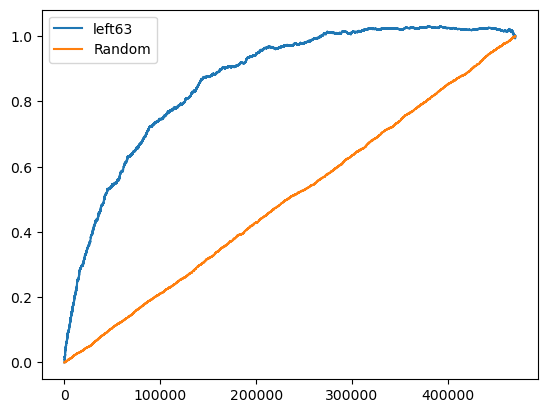

In [15]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v4,
              treatments=[1], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left853    0.820743
Random     0.491726
dtype: float64
****************************************


[left853    0.820743
 Random     0.491726
 dtype: float64]

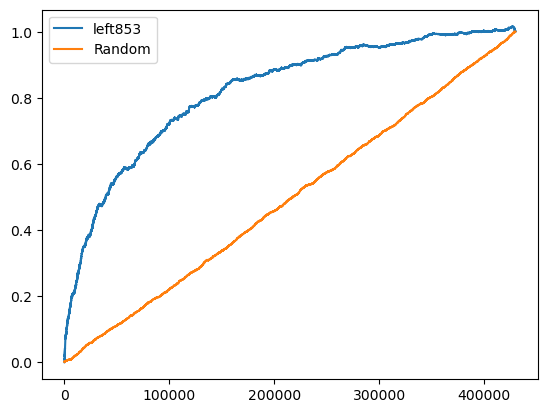

In [16]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v4,
              treatments=[2], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left853'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left65    0.859687
Random    0.497064
dtype: float64
****************************************


[left65    0.859687
 Random    0.497064
 dtype: float64]

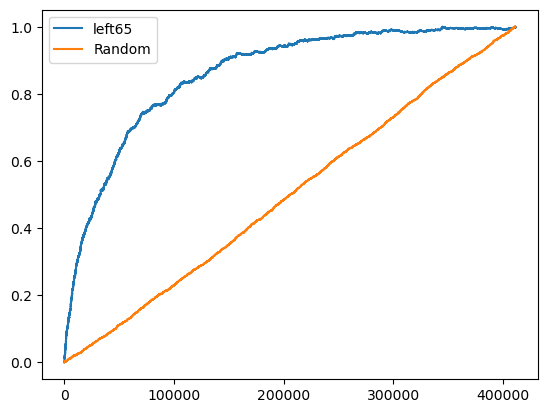

In [17]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v4,
              treatments=[3], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left65'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

left853_minus_left63    0.402324
Random                  0.635506
dtype: float64
****************************************
left65_minus_left63    0.916794
Random                 0.476501
dtype: float64
****************************************


[left853_minus_left63    0.402324
 Random                  0.635506
 dtype: float64,
 left65_minus_left63    0.916794
 Random                 0.476501
 dtype: float64]

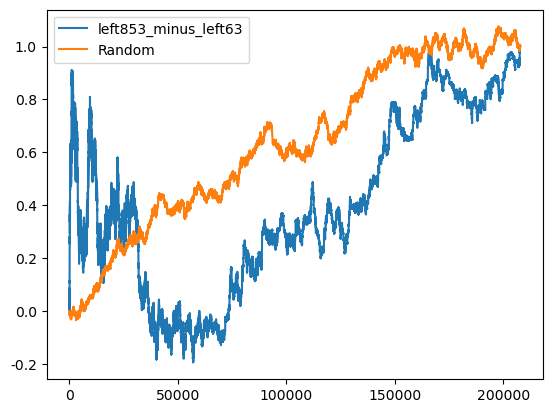

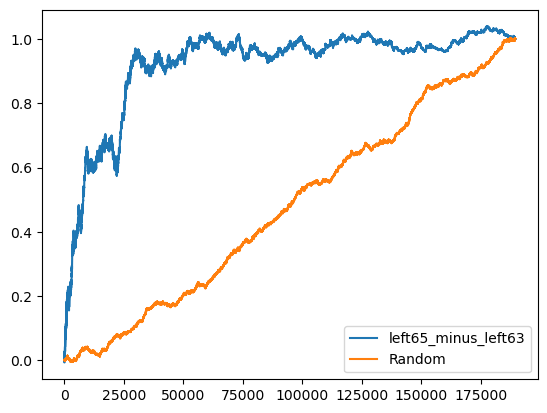

In [18]:
vis.draw_auuc(BASE_FMT_v4,
              # 分别评估: 基底(组1), 差值A(组2), 差值B(组3)
              treatments=[2,3],  
              
              ite_names=['left853_minus_left63', 'left65_minus_left63'],  
              
              label_col='label',  
              curve_type='auuc',
              real_treatment='real_treatment', 

              control_group_name=1,  
              
              show_curve=1
        )

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v133,
              treatments=[5], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left65_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=6, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v133,
              treatments=[6], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

## 逐天euen

In [ ]:
BASE_FMT_v7 = spark.sql("""
with base as (
    select *,
        finish_cnt_7d as label,
        cast((nvl(remind_cost, 0.0) + nvl(msg_coupon_cost, 0.0)) as double) as cost
    from dm.ut_alg_flowback_msg_outcall_label_di
    where dt between '2026-04-01' and '2026-04-22'
    and dt != '2026-04-08'
    and new_exp = '迭代流量'
    and ((group_name_eve in ('留存6张5元', '8元留存5张3', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select 
        bs.*,
        case when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'control_group' then 0
             else null
        end as real_treatment,
        mapping_data.treatment as model_treatment,
        

        mapping_data.left65_minus_left63,
        mapping_data.left853_minus_left63,
        mapping_data.left63,


        (nvl(mapping_data.left63, 0.0) + nvl(mapping_data.left65_minus_left63, 0.0)) as left65,
        (nvl(mapping_data.left63, 0.0) + nvl(mapping_data.left853_minus_left63, 0.0)) as left853,
        
        mapping_data.cost_1,
        mapping_data.cost_2,
        mapping_data.cost_3
    from base bs
    join (
       select 
            pid,
            date_add(label_dt, 1) as dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853_minus_left63,
            uplift_3 as left65_minus_left63,
            cost_1,
            cost_2,
            cost_3
        from dm.ut_alg_flowback_app_package_euen_26_v123_month_3_3_model_inference_di



        where label_dt between '2026-03-31' and '2026-04-21' 
        and label_dt != '2026-04-07'
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)
select *
from prediction_agg
""").toPandas()

BASE_FMT_v7.head(25)

    

In [ ]:
BASE_FMT_v132.shape

In [ ]:
BASE_FMT_v132['real_treatment'].value_counts(dropna=False)

In [ ]:

def calculate_diff_rate(data, prob_name, target_treatments):# target_treatments=[0, 6]  prob_name=['left63']
    result = pd.DataFrame()
    for prob in prob_name:
        data['prob_binned'] = pd.qcut(data[prob], q=10, labels=False, duplicates='drop')   # 根据left63(6)的概率值分10桶
        bucket_summary_df = pd.DataFrame()
        for bin in range(10): 
            bin_data = data[(data['prob_binned'] == bin) & (data['real_treatment'].isin(target_treatments))]
            treatment_counts = bin_data['real_treatment'].value_counts().sort_index()   # 第 bin个桶里 0 6 各有多少 样本
            total_count = len(bin_data)
            proportions = treatment_counts / total_count   # 第bin个桶里 0 6 各自占比 （最终表 每一列第一行+第二行=1）  索引是 0 6

            proportions_df = proportions.rename('proportion').reset_index()
            proportions_df.columns = ['real_treatment', f'bin_{bin}'] 
            if bucket_summary_df.empty:
                bucket_summary_df = proportions_df
            else:
                bucket_summary_df = pd.merge(bucket_summary_df, proportions_df, on='real_treatment', how='outer')
        bucket_summary_df['diff_rate'] = bucket_summary_df[['bin_0', 'bin_1', 'bin_2', 'bin_3', 'bin_4', 'bin_5', 'bin_6', 'bin_7', 'bin_8', 'bin_9']].max(axis=1) - bucket_summary_df[['bin_0', 'bin_1', 'bin_2', 'bin_3', 'bin_4', 'bin_5', 'bin_6', 'bin_7', 'bin_8', 'bin_9']].min(axis=1)
        #  每一行的最大值减最小值
        bucket_summary_df['prob_name'] = prob   # ['left63']
        result = pd.concat([result, bucket_summary_df], axis=0, ignore_index=True)
    return result

In [ ]:
target_treatments = [0, 6]
prob_name = ['left63']
calculate_diff_rate(BASE_FMT_v132, prob_name, target_treatments)

In [ ]:
# ==========================================
# 1. 单拆：在 DataFrame 中计算绝对增益
# ==========================================
# left65 = 基底(left63) + left65残差
BASE_FMT_v7['left65'] = BASE_FMT_v7['left63'] + BASE_FMT_v7['left65_minus_left63']

# left853(即你的 prob8left53) = 基底(left63) + left853残差
BASE_FMT_v7['left853'] = BASE_FMT_v7['left63'] + BASE_FMT_v7['left853_minus_left63']

# 可以打印一下确认是否计算正确
# print(BASE_FMT_v1[['left63', 'left853', 'left65']].head())


# ==========================================
# 2. 评估：传入单拆后的列名，同时评估 3 个组
# ==========================================
# 1 对应 left63
# 2 对应 8元留存5张3 (left853)
# 3 对应 留存6张5元 (left65)

vis.draw_auuc(BASE_FMT_v7,
              treatments=[1,2, 3],  # 一次性传入 3 个干预组
              ite_names=['left63', 'left853', 'left65'],  # 对应放入你刚刚单拆出来的绝对增量列名
              label_col='label',  
              curve_type='auuc',
              real_treatment='real_treatment', 
              control_group_name= 0,  # 对应 3 个组的对照组，注意要用列表包裹
              show_curve=1
        )

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v132,
              treatments=[5], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left65_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=6, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v132,
              treatments=[6], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

## base_dfcl

In [ ]:
BASE_FMT_v131 = spark.sql("""
with base as (
    select *,
    cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
    finish_cnt_7d as pv_label_7d,
    cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d
    from growstrategy.ut_alg_flowback_msg_label_v2_di
    where dt between '2025-09-01' and '2025-09-14'
    and new_exp = '迭代流量'
    and ((flowtree_group_name = '探索' and group_name_eve in ('555', '5折5折5折(cap10)', '留存6张5元', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select *,
        bs.pid, bs.dt,
        uv_label as uv_label,
        pv_label_7d as label,
        group_name_eve,
        case when group_name_eve = '留存6张3元' then 6
            when group_name_eve = '留存6张5元' then 5
            when group_name_eve = '5折5折5折(cap10)' then 4
            when group_name_eve = '555' then 1
            when group_name_eve = 'control_group' then 0
            else null
        end as real_treatment
    from (
        select * from base
    ) bs
    join (
       select 
            pid,
            label_dt as dt,
            treatment,
            uplift_1 as prob555_minus_left63,
            uplift_4 as probcap10_minus_left63,
            uplift_5 as left65_minus_left63,
            uplift_6 as left63,
            cost_1 as cost_1,
            cost_4 as cost_4,
            cost_5 as cost_5,
            cost_6 as cost_6
            
        from growstrategy.ut_mkt_backflow_multi_treat_mmoe1_v216_dfcl000000_new_uplift_epoch2_1_model_inference_di

        where label_dt between '2025-09-01' and '2025-09-14'   
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)
select *
from prediction_agg
"""
).toPandas()
BASE_FMT_v131.head(25)

In [ ]:

def calculate_diff_rate(data, prob_name, target_treatments):# target_treatments=[0, 6]  prob_name=['left63']
    result = pd.DataFrame()
    for prob in prob_name:
        data['prob_binned'] = pd.qcut(data[prob], q=10, labels=False, duplicates='drop')   # 根据left63(6)的概率值分10桶
        bucket_summary_df = pd.DataFrame()
        for bin in range(10): 
            bin_data = data[(data['prob_binned'] == bin) & (data['real_treatment'].isin(target_treatments))]
            treatment_counts = bin_data['real_treatment'].value_counts().sort_index()   # 第 bin个桶里 0 6 各有多少 样本
            total_count = len(bin_data)
            proportions = treatment_counts / total_count   # 第bin个桶里 0 6 各自占比 （最终表 每一列第一行+第二行=1）  索引是 0 6

            proportions_df = proportions.rename('proportion').reset_index()
            proportions_df.columns = ['real_treatment', f'bin_{bin}'] 
            if bucket_summary_df.empty:
                bucket_summary_df = proportions_df
            else:
                bucket_summary_df = pd.merge(bucket_summary_df, proportions_df, on='real_treatment', how='outer')
        bucket_summary_df['diff_rate'] = bucket_summary_df[['bin_0', 'bin_1', 'bin_2', 'bin_3', 'bin_4', 'bin_5', 'bin_6', 'bin_7', 'bin_8', 'bin_9']].max(axis=1) - bucket_summary_df[['bin_0', 'bin_1', 'bin_2', 'bin_3', 'bin_4', 'bin_5', 'bin_6', 'bin_7', 'bin_8', 'bin_9']].min(axis=1)
        #  每一行的最大值减最小值
        bucket_summary_df['prob_name'] = prob   # ['left63']
        result = pd.concat([result, bucket_summary_df], axis=0, ignore_index=True)
    return result

In [ ]:
target_treatments = [0, 6]
prob_name = ['left63']
calculate_diff_rate(BASE_FMT_v131, prob_name, target_treatments)

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v131,
              treatments=[1], # 这边写的是real_treatment中表示干预的符号
              ite_names=['prob555_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=6, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v131,
              treatments=[5], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left65_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=6, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v131,
              treatments=[6], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

## zlin_0.05

In [ ]:
BASE_FMT_v131 = spark.sql("""
with base as (
    select *,
    cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
    finish_cnt_7d as pv_label_7d,
    cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d
    from growstrategy.ut_alg_flowback_msg_label_v2_di
    where dt between '2025-11-01' and '2025-11-14'
    and new_exp = '迭代流量'
    and ((flowtree_group_name = '探索' and group_name_eve in ('555', '5折5折5折(cap10)', '留存6张5元', '留存6张3元')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select *,
        bs.pid, bs.dt,
        uv_label as uv_label,
        pv_label_7d as label,
        group_name_eve,
        case when group_name_eve = '留存6张3元' then 6
            when group_name_eve = '留存6张5元' then 5
            when group_name_eve = '5折5折5折(cap10)' then 4
            when group_name_eve = '555' then 1
            when group_name_eve = 'control_group' then 0
            else null
        end as real_treatment
    from (
        select * from base
    ) bs
    join (
       select 
            pid,
            label_dt as dt,
            treatment,
            uplift_1 as prob555_minus_left63,
            uplift_4 as probcap10_minus_left63,
            uplift_5 as left65_minus_left63,
            uplift_6 as left63,
            cost_1 as cost_1,
            cost_4 as cost_4,
            cost_5 as cost_5,
            cost_6 as cost_6
            
        from growstrategy.ut_mkt_backflow_multi_treat_euen_v212_ziln124_new_2_new_uplift_model_inference_di

        where label_dt between '2025-10-31' and '2025-11-13'   --   v21
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)
select *
from prediction_agg
"""
).toPandas()
BASE_FMT_v131.head(25)

In [ ]:

def calculate_diff_rate(data, prob_name, target_treatments):# target_treatments=[0, 6]  prob_name=['left63']
    result = pd.DataFrame()
    for prob in prob_name:
        data['prob_binned'] = pd.qcut(data[prob], q=10, labels=False, duplicates='drop')   # 根据left63(6)的概率值分10桶
        bucket_summary_df = pd.DataFrame()
        for bin in range(10): 
            bin_data = data[(data['prob_binned'] == bin) & (data['real_treatment'].isin(target_treatments))]
            treatment_counts = bin_data['real_treatment'].value_counts().sort_index()   # 第 bin个桶里 0 6 各有多少 样本
            total_count = len(bin_data)
            proportions = treatment_counts / total_count   # 第bin个桶里 0 6 各自占比 （最终表 每一列第一行+第二行=1）  索引是 0 6

            proportions_df = proportions.rename('proportion').reset_index()
            proportions_df.columns = ['real_treatment', f'bin_{bin}'] 
            if bucket_summary_df.empty:
                bucket_summary_df = proportions_df
            else:
                bucket_summary_df = pd.merge(bucket_summary_df, proportions_df, on='real_treatment', how='outer')
        bucket_summary_df['diff_rate'] = bucket_summary_df[['bin_0', 'bin_1', 'bin_2', 'bin_3', 'bin_4', 'bin_5', 'bin_6', 'bin_7', 'bin_8', 'bin_9']].max(axis=1) - bucket_summary_df[['bin_0', 'bin_1', 'bin_2', 'bin_3', 'bin_4', 'bin_5', 'bin_6', 'bin_7', 'bin_8', 'bin_9']].min(axis=1)
        #  每一行的最大值减最小值
        bucket_summary_df['prob_name'] = prob   # ['left63']
        result = pd.concat([result, bucket_summary_df], axis=0, ignore_index=True)
    return result

In [ ]:
target_treatments = [0, 6]
prob_name = ['left63']
calculate_diff_rate(BASE_FMT_v131, prob_name, target_treatments)

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v131,
              treatments=[1], # 这边写的是real_treatment中表示干预的符号
              ite_names=['prob555_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=6, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v131,
              treatments=[5], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left65_minus_left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=6, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [ ]:
# BASE中需要有label有没有完单、predict值表示delta cvr值、真实干预列、oneid列就行
vis.draw_auuc(BASE_FMT_v131,
              treatments=[6], # 这边写的是real_treatment中表示干预的符号
              ite_names=['left63'],# 放预测值的列名
              label_col='label',  # 这边放的是表示label那一列的列名，注意label和real_treatment的区别
              curve_type='auuc',
              real_treatment='real_treatment', # 这边放的是表示真实干预情况的那一列列名
              control_group_name=0, # 这边写的是real_treatment中表示控制组的符号
              show_curve=1
        ) 

In [ ]:
spark.sql("""
    select 
      count(dm_user_base_oneid_info_last_use_htm) as use_htm_cnt,
      count(dm_user_deal_pub_rfm_bus_score_rank) as bus_score_cnt
    from dm.ut_alg_flowback_msg_outcall_feature_train_di 
    where dt = '2026-03-03'
""").show()

In [ ]:
import datetime
from itertools import product
def smart_generate_dt_list(start_dt, degree_days, step=1, format="%Y-%m-%d", flag=1, 
                          ignore_dts=[]):
    
    strptime, strftime = datetime.datetime.strptime, datetime.datetime.strftime
    
    gen_dts = []
    curr_dt = start_dt
    
    while len(gen_dts)<degree_days:
        if curr_dt not in ignore_dts:
            gen_dts.append(curr_dt)
        
        __dt = strftime(strptime(curr_dt, format) - datetime.timedelta(1), format)
        if flag == 1:
            __dt = strftime(strptime(curr_dt, format) + datetime.timedelta(1), format)
            
        curr_dt = __dt
    
        
    gen_dts = sorted(gen_dts)
    if gen_dts[-1] != start_dt:
        gen_dts.append(start_dt)
    return sorted(gen_dts)[-degree_days:]

def calculate_delta_metrics(df, group_name_1, group_name_2):
    # 计算通补delta cac、delta cvr函数
    # 取出当前 bucket 下的数据
    bucket_data = df

    # 分别取出 group_name_eve 为 group_name_1 和 group_name_2 的数据
    data_1 = bucket_data[bucket_data['group_name_eve'] == group_name_1]
    data_2 = bucket_data[bucket_data['group_name_eve'] == group_name_2]

    # 计算各自的总数量和 cost_7d 的总和
    total_count_1 = len(data_1)
    total_cost_1 = data_1['cost_7d'].sum()
    total_cvr_1 = data_1['pv_label_7d'].sum()

    total_count_2 = len(data_2)
    total_cost_2 = data_2['cost_7d'].sum()
    total_cvr_2 = data_2['pv_label_7d'].sum()

    # 计算 delta_cac
    cac_1 = total_cost_1 / total_count_1 if total_count_1 > 0 else 0
    cac_2 = total_cost_2 / total_count_2 if total_count_2 > 0 else 0

    cvr_1 = total_cvr_1 / total_count_1 if total_count_1 > 0 else 0
    cvr_2 = total_cvr_2 / total_count_2 if total_count_2 > 0 else 0

    delta_cost = cac_1 - cac_2
    delta_cvr = cvr_1 - cvr_2
    delta_cac = delta_cost / delta_cvr if delta_cvr != 0 else 0

    return delta_cac, delta_cvr

def process_df(df, control_name, bucket_name = 'bucket_name'):
    """
    :param df: DataFrame, with columns ['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost']
    :param control_name: string, 控制组实验名称
    :return: DataFrame
    """
    new_df = pd.DataFrame()
    for name, group in df.groupby(['bucket_name']): # 将每个桶中不同折扣的数据进行放缩
        sample = group['in_uv'].sum() # 该分桶下的总人数，也即某一桶下所有treatment总和
        group['zoom_sample'] = sample # 该分桶下的总人数
        group['zoom_first'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_uv, axis=1)
        group['zoom_finish'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_pv, axis=1)
        group['zoom_cost'] = group.apply(lambda row: row.zoom_sample/row.in_uv * float(row.total_cost), axis=1)
        group['cvr_pv'] = group.apply(lambda row: row.zoom_finish/row.zoom_sample if row.zoom_sample != 0 else 0, axis=1)
        control_finish = group[group['exp_name'] == control_name]['zoom_finish'].sum()
#         control_first = group[group['exp_name'] == control_name]['zoom_first'].sum()
        control_cost = group[group['exp_name'] == control_name]['zoom_cost'].sum()
        group['zoom_delta_cost'] = group.apply(lambda row: row.zoom_cost - control_cost, axis=1)
        group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish, axis=1)
#         group['zoom_delta_first'] = group.apply(lambda row: row.zoom_first - control_first, axis=1)
        new_df = new_df.append(group, ignore_index=True)
    return new_df

def data_prepare(df, para, bucket_col, group_name, control_name):
    """
    df: DataFrame, 数据源
    para: dict, 补贴形式
    bucket_col: string, 表示用户所在分桶的列
    group_name: string, 表示用户实际发券的分组
    control_name: string, Control组名称
    """
    dis_num = len(para)  # 补贴种类
    bucket_info = df[bucket_col].unique()  # 用户分桶信息
    bucket_num = len(bucket_info)  # 桶数量
    N = dis_num * bucket_num
    Y = np.ones((1, N))  # 目标人数最多 # 优化目标
    C = np.ones((1, N))  # 整体成本符合要求
    for i in range(bucket_num):  # 遍历桶
        bucket_id = bucket_info[i]  # 桶编码
        part_df = df[df[bucket_col] == bucket_id]  # 相应桶的数据
        sub = i * dis_num  # 索引位置
        used = set()
        if part_df[part_df[group_name] == control_name].empty:
            raise ValueError("出现空白为空的情况")
        for _, row in part_df.iterrows():
            if row[group_name] not in para:
                continue
            if row[group_name] == control_name:
                Y[0][sub + para[row[group_name]]] = row.zoom_delta_finish  # delta_CAC约束
                C[0][sub + para[row[group_name]]] = 0
            else:
                finish_uv = row.zoom_delta_finish  # delta_CAC约束
                coupon_cost = row.zoom_cost
                if finish_uv == 0 and coupon_cost == 0:
                    finish_uv = -100  # 保证不会被选择
                    coupon_cost = 0
                Y[0][sub + para[row[group_name]]] = finish_uv
                C[0][sub + para[row[group_name]]] = coupon_cost
            used.add(row[group_name])
        if len(used) != dis_num:
            raise ValueError("折扣数量不一致")

    C = C.reshape(-1)
    Y = Y.reshape(-1)
    return Y, C, bucket_info

def ortools_coupon(target, constraint, bucket_num, set_cost, para):
    """
    调用谷歌ortools包求解
    :param target: 目标表达式
    :param constraint: 约束表达式
    :param bucket_num: int, 桶数量
    :param set_cost: float, 成本信息
    :param para: dict, 补贴信息
    :return:
    """
    discount_num = len(para)
    N = len(target)
    st_exp_cost, obj_exp = None, None
    # 模型
    optimization_problem_type = 'SCIP'
    solver = pywraplp.Solver.CreateSolver(optimization_problem_type)
    # 创建N个二进制变量
    x = [solver.IntVar(0, 1, 'x' + str(i)) for i in range(N)]
    # 优化目标：每个桶中不同券的delta_finish
    for i in range(N):
        if obj_exp is None:
            obj_exp = x[i] * target[i]
        else:
            obj_exp = obj_exp + x[i] * target[i]
#     print('obj_exp:')
#     print(obj_exp)
    # 成本表达式: 每个桶中不同券的的cost 累加
    for i in range(N):
        if st_exp_cost is None:
            st_exp_cost = x[i] * constraint[i]
        else:
            st_exp_cost = st_exp_cost + x[i] * constraint[i]
#     print('st_exp_cost:')
#     print(st_exp_cost)
    # 约束条件1: 每个桶只能选择一种折扣
    for i in range(bucket_num):
        bucket_vars = [x[j] for j in range(i * discount_num, (i + 1) * discount_num)]
        solver.Add(solver.Sum(bucket_vars) == 1)
    # 约束条件2: 成本约束
    solver.Add(st_exp_cost <= set_cost * obj_exp)   # obj_exp：delta_finish
    # 定义优化目标
    solver.Maximize(obj_exp) 
    # 调用求解器
    result_status = solver.Solve()
    res = []
    max_finish = 0
    if result_status == pywraplp.Solver.OPTIMAL:
        for i in range(len(x)):
            res.append(x[i].solution_value())
        max_finish = solver.Objective().Value()

    return (max_finish, res)

def or_convert(res, bucket_info, para):
    """
    :param res: 求解结果
    :param bucket_info: 桶信息
    :param para: 补贴信息
    :return: dict, 每个城市具体发券情况
    """
    new_para = dict((v, k) for k, v in para.items())
    discount_num = len(para)  # 补贴券数量
    coupon_ans = {}
    bucket_num = len(bucket_info) # 桶数量
    for i in range(bucket_num):
        tag = 0
        for j in range(i * discount_num, (i + 1) * discount_num):
            if res[j] == 1:
                index = j - i * discount_num
                coupon_ans[bucket_info[i]] = new_para[index]
                tag = 1
                break
        if tag == 0:
            try:
                coupon_ans[bucket_info[i]] = new_para[0]
            except:
                raise ValueError("未设置默认发券情况")
    return coupon_ans

# 引入对预测集出现新的组合桶，也即打上bucket_num=-1的桶的给出策略处理：通补线上基线

def mock_use(df, coupon_ans, control_name, default_coupon, all_default_coupon_flag=False):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0
    
    # 处理传入的 coupon_ans 中的折扣
    for key, value in coupon_ans.items():
        treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
        control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    # 处理 bucket_name 为 -1 的情况
    default_keys = [-1]
    for key in default_keys:
        if key in df['bucket_name'].values:
            if all_default_coupon_flag:
                print("into all default & -1")
                value = coupon_ans[0] # 按通补指定的券来
                print(value)
            else:
                value = default_coupon # 为-1的桶分配线上的基线券
            treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
            control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
            if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
                # 未匹配到数据，继续处理下一个 key
                continue
            treat_sample += treat_df['zoom_sample'].values[0]
            treat_finish_uv += treat_df['zoom_first'].values[0]
            treat_finish_pv += treat_df['zoom_finish'].values[0]
            treat_cost += treat_df['zoom_cost'].values[0]
            control_sample += control_df['zoom_sample'].values[0]
            control_finish_uv += control_df['zoom_first'].values[0]
            control_finish_pv += control_df['zoom_finish'].values[0]
            control_cost += control_df['zoom_cost'].values[0]
            if treat_sample != control_sample:
                raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost, 
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac]

# 仿真时采用新聚合方式模拟
def mock_use_simulation(df, control_name):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0

    # 遍历每个桶，取桶名对应的干预动作作为treat的模拟数据
    for value in list(df['bucket_name'].unique()):
        treat_df = df[(df['bucket_name'] == value) & (df['exp_name'] == df['bucket_value'])] #取bucket_value的券对应的RCT数据
        control_df = df[(df['bucket_name'] == value) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost,
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac]

def split_small_data(small_data, columns, all_columns, min_count):
    # 仅使用指定列进行分组和统计，但保留所有列
    combination_counts = small_data.groupby(columns).size().reset_index(name='counts')

    # 获取大于等于最小数量的组合
    large_combinations = combination_counts[combination_counts['counts'] >= min_count]
    small_combinations = combination_counts[combination_counts['counts'] < min_count]

    # 根据组合数量大于等于最小数量的组合，拆出数据，并保留完整的列
    large_sample_data = small_data.merge(large_combinations[columns], on=columns, how='inner')
    large_sample_data = large_sample_data[all_columns]

    # 根据组合数量小于最小数量的组合，拆出数据，并保留完整的列
    small_sample_data = small_data.merge(small_combinations[columns], on=columns, how='inner')
    small_sample_data = small_sample_data[all_columns]

    # 计算大组合和小组合的数据统计
    large_use_combinations = large_sample_data.groupby(all_columns).size().reset_index(name='counts')
    small_use_combinations = small_sample_data.groupby(all_columns).size().reset_index(name='counts')

    return large_sample_data, small_sample_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations

def generate_bucket_mapping_final(stage_combinations, all_columns, stage_columns):
    bucket_mapping = {}
    bucket_id = 0
    
    # 创建一个字典来存储每个组合的bucket_id，键为base_combination， 值为bucket_id
    combination_to_bucket = {}

    # 处理每个阶段的大样本数的组合
    for stage_idx, (large_combinations, small_combinations, columns) in enumerate(stage_combinations):
        if large_combinations is not None and not large_combinations.empty:
            for index, row in large_combinations.iterrows():
                # combination是完整组合值 (0.1 0.7 0.2 0.3)
                combination = tuple(row[col] for col in all_columns)
                # 对应于降级后的组合 如(0.8 0.2 8888 8888), (0.7, 8888, 8888, 8888), (0.6, 8888, 8888, 8888)
                base_combination = tuple(row[col] for col in columns) + (8888,) * (len(all_columns) - len(columns))
                # 如果此时字典没有这种base_combination，则为这种组合分配新桶号
                if base_combination not in combination_to_bucket:
                    combination_to_bucket[base_combination] = bucket_id
                    bucket_id += 1
                if combination_to_bucket[base_combination] not in bucket_mapping:
                    bucket_mapping[combination_to_bucket[base_combination]] = []
                bucket_mapping[combination_to_bucket[base_combination]].append(combination)
    
    # 处理最后一个阶段的小样本数的组合，归为一个桶
    if small_combinations is not None and not small_combinations.empty:
        final_bucket_id = bucket_id
        for index, row in small_combinations.iterrows():
            combination = tuple(row[col] for col in all_columns)
            if final_bucket_id not in bucket_mapping:
                bucket_mapping[final_bucket_id] = []
            bucket_mapping[final_bucket_id].append(combination)
    
    return bucket_mapping

def simulate_and_plot(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon):
    """
    运行仿真并收集结果，绘制训练集和测试集结果曲线图。
    Parameters:
    Y: 
    C: 
    bucket_info: list, 桶信息
    group_name_list: 指定讨论干预组
    cost_list: list, 成本列表
    discount_para: dict, 折扣参数
    processed_data: DataFrame, 训练数据
    next_processed_data: DataFrame, 测试数据
    ortools_coupon: function, 计算优惠券的函数
    or_convert: function, 转换优惠券信息的函数
    mock_use: function, 模拟使用优惠券的函数
    """

    # 初始化结果列表
    train_x = []
    train_y = []
    test_x = []
    test_y = []
    discount_res_list = []
    discount_res= {}
    train_list = []
    test_list = []
    tongbu_list = []
    tongbu_all_list = []
    
    color_mapping = {
    '555': 'brown',
    '留存6张3元': 'darkgreen'
    # add others...
}
    

    # 运行仿真并收集结果
    for cost_value in cost_list:
        max_finish, res = ortools_coupon(Y, C, len(bucket_info), cost_value, discount_para)
        discount_res = or_convert(res, bucket_info, discount_para)
        discount_res_list.append(discount_res)

        # 计算训练集结果
        train_ans = mock_use(processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)#'5折5折5折(cap5)'
        # 计算测试集结果
        test_ans = mock_use(next_processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)

        # 提取结果并添加到列表中
        train_x.append(train_ans[-1])
        train_y.append(train_ans[-3])
        test_x.append(test_ans[-1])
        test_y.append(test_ans[-3])
        train_list.append([cost_value, train_ans[-1], train_ans[-3]])
        test_list.append([cost_value, test_ans[-1], test_ans[-3]])

    use_group_name_list = [name for name in group_name_list if name != control_name]
    coordinates = {}
    coordinates_total = {}

    for group_name in use_group_name_list:
        # 计算遍历所有桶，指定发放同一种券的结果图
        discount_dict = {key: group_name for key in discount_res}
        train_ans = mock_use(processed_data, discount_dict, control_name=control_name, default_coupon=group_name, all_default_coupon_flag=True)
        test_ans = mock_use(next_processed_data, discount_dict, control_name=control_name, default_coupon=group_name, all_default_coupon_flag=True)
        # Extract coordinates
        train_x_single, train_y_single = train_ans[-1], train_ans[-3]
        test_x_single, test_y_single = test_ans[-1], test_ans[-3]
        tongbu_list.append([train_x_single, train_y_single, test_x_single, test_y_single])
        
        # Store the coordinates in the dictionary
        coordinates[group_name] = {
            'train': (train_x_single, train_y_single),
            'test': (test_x_single, test_y_single)
        }
    
    # 绘制训练集结果曲线图
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(train_x, train_y, marker='.', label='Train')
    for group_name, data in coordinates.items():
        train_x_single, train_y_single = data['train']
        plt.scatter([train_x_single], [train_y_single], color=color_mapping.get(group_name, 'blue'), label=f'train_{group_name}_single', marker='.')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Train Results')
    plt.legend()

    # 绘制测试集结果曲线图
    plt.subplot(1, 2, 2)
    plt.plot(test_x, test_y, marker='.', label='Test')
    
    # Plotting test data points
    for group_name, data in coordinates.items():
        test_x_single, test_y_single = data['test']
        plt.scatter([test_x_single], [test_y_single], color=color_mapping.get(group_name, 'blue'), label=f'test_{group_name}_single', marker='.')
    
    
    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Test Results')
    plt.legend()

    plt.tight_layout()
    plt.show()
    
    return discount_res_list, train_list, test_list, tongbu_list

def simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para,
                          processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon,
                          mock_use_simulation, simulation_flag):
    """
    运行仿真并收集结果，绘制训练集和测试集结果曲线图。
    Parameters:
    Y:
    C:
    bucket_info: list, 桶信息
    group_name_list: 指定讨论干预组
    cost_list: list, 成本列表
    discount_para: dict, 折扣参数
    processed_data: DataFrame, 训练数据
    next_processed_data: DataFrame, 测试数据
    ortools_coupon: function, 计算优惠券的函数
    or_convert: function, 转换优惠券信息的函数
    mock_use: function, 模拟使用优惠券的函数
    mock_use_simulation: function, 新版模拟使用优惠券的函数
    simulation_flag: bool, 是否用新版模拟仿真效果
    """

    # 初始化结果列表
    train_x = []
    train_y = []
    test_x = []
    test_y = []
    discount_res_list = []
    discount_res = {}
    train_list = []
    test_list = []
    tongbu_list = []
    tongbu_all_list = []

    color_mapping = {
        '555': 'brown',
        '留存6张3元': 'darkgreen'
        # add others...
    }

    # 运行仿真并收集结果
    for cost_value in cost_list:
        max_finish, res = ortools_coupon(Y, C, len(bucket_info), cost_value, discount_para)
        print('max_finish', max_finish)
#         print('res', res)
        discount_res = or_convert(res, bucket_info, discount_para)
#         print('discount_res', discount_res)
        discount_res[-1] = default_coupon  # 结果字典中添加关联不上的桶号-1发放兜底券
        discount_res_list.append(discount_res)

        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_res)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id #仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])
            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_res)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id  # 仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            # 计算训练集结果
            train_ans = mock_use(processed_data, discount_res, control_name='DS空白',
                                 default_coupon=default_coupon)  # '5折5折5折(cap5)'
            # 计算测试集结果
            test_ans = mock_use(next_processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)

        # 提取结果并添加到列表中
        train_x.append(train_ans[-1])
        train_y.append(train_ans[-3])
        test_x.append(test_ans[-1])
        test_y.append(test_ans[-3])
        train_list.append([cost_value, train_ans[-1], train_ans[-3], train_ans[-4], train_ans[-3]/train_ans[-4]])
        test_list.append([cost_value, test_ans[-1], test_ans[-3], test_ans[-4], test_ans[-3]/test_ans[-4]])

    use_group_name_list = [name for name in group_name_list if name != control_name]
    coordinates = {}
    coordinates_total = {}

    for group_name in use_group_name_list:
        # 计算遍历所有桶，指定发放同一种券的结果图
        mid = 5  # len(discount_res_list)//2
        discount_dict = discount_res_list[mid]
        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_dict)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])
            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_dict)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            train_ans = mock_use(processed_data, discount_dict, control_name=control_name, default_coupon=group_name,
                                 all_default_coupon_flag=True)
            test_ans = mock_use(next_processed_data, discount_dict, control_name=control_name,
                                default_coupon=group_name, all_default_coupon_flag=True)
        # Extract coordinates
        train_x_single, train_y_single = train_ans[-1], train_ans[-3]
        test_x_single, test_y_single = test_ans[-1], test_ans[-3]
        tongbu_list.append([train_x_single, train_y_single, test_x_single, test_y_single])

        # Store the coordinates in the dictionary
        coordinates[group_name] = {
            'train': (train_x_single, train_y_single),
            'test': (test_x_single, test_y_single)
        }

        # 真正彻底的通补
        train_x_total, train_y_total = calculate_delta_metrics(train_df, group_name, control_name)
        test_x_total, test_y_total = calculate_delta_metrics(val_df, group_name, control_name)
        tongbu_all_list.append([train_x_total, train_y_total, test_x_total, test_y_total])

        coordinates_total[group_name] = {
            'train': (train_x_total, train_y_total),
            'test': (test_x_total, test_y_total)
        }

    # 绘制训练集结果曲线图
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(train_x, train_y, marker='.', label='Train')
    for group_name, data in coordinates.items():
        train_x_single, train_y_single = data['train']
        plt.scatter([train_x_single], [train_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'train_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        train_x_total, train_y_total = data['train']
        plt.scatter([train_x_total], [train_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'train_{group_name}_total', marker='.')
    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Train Results')
    plt.legend()

    # 绘制测试集结果曲线图
    plt.subplot(1, 2, 2)
    plt.plot(test_x, test_y, marker='.', label='Test')

    # Plotting test data points
    for group_name, data in coordinates.items():
        test_x_single, test_y_single = data['test']
        plt.scatter([test_x_single], [test_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'test_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        test_x_total, test_y_total = data['test']
        plt.scatter([test_x_total], [test_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'test_{group_name}_total', marker='.')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Test Results')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return discount_res_list, train_list, test_list, tongbu_list, tongbu_all_list

def assign_bucket_num(row, columns, reverse_mapping, train_flag=False):
    prob_tuple = tuple(row[col] for col in columns)
    if train_flag and reverse_mapping.get(prob_tuple) is None:
        print("训练集组合出现与mapping表不重合部分:" + str(prob_tuple))
#         raise ValueError("训练集组合出现与mapping表不重合部分")
    return reverse_mapping.get(prob_tuple, -1)  # -1 表示没有找到对应的 bucket


def main_try(use_train_all, combined_val_data, group_name_list, control_name,cost_list,
              all_columns, stages, discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag =True):
    """
    调用函数，执行规划
    :param sql1: 查询规划训练数据
    :param sql2: 查询规划验证数据
    :param train_dt: 规划依赖数据 查询时间段
    :param val_dt: 规划验证数据依赖 时间段
    :param group_name_list: 指定讨论干预组
    :param control_name: 指定控制组名称，如'DS空白'
    :param cost_list: 规划的折扣范围—-定义成本
    :param all_columns: 规划的折扣范围—-定义成本
    :param stage_params: 规划的折扣范围—-定义成本
    :param method: 暂未使用, 指定不同规划方式。当method为1时, 选择根据分桶桶合并来进行规划、method为2时，选择聚类合并
    :return:
    """
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    if stages:
        # 执行多阶段分层拆分
        use_data_input = train_df.copy()
        stage_results = []
        if combinations:
            # 使用全部分桶字段定义枚举值列表
            lists = []
            for i in all_columns:
                if i == 'fin_order_mini_28d':
                    lists.append([0.0, 1.0])
                else:
                    lists.append(pd.Categorical([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]))

            # 使用itertools.product生成所有组合
            all_combinations = pd.DataFrame(list(product(*lists)), columns = all_columns)

            # 基于所有组合创建和use_data_input字段一致的dataframe，其余字段置为none
            for column in use_data_input.columns:
                if column not in all_combinations.columns:
                    all_combinations[column] = np.nan #pd.NA
            all_combinations = all_combinations[use_data_input.columns.tolist()]
            use_data_input = use_data_input.append(all_combinations, ignore_index=True)
        current_data = use_data_input

        for stage in stages:
            columns, min_count = stage
            large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations = split_small_data_debug(current_data, columns, all_columns, min_count)
            current_data = small_data
            stage_results.append((large_use_combinations, small_use_combinations, columns))

        # 获取最后阶段的组合数据
        large_use_combinations = stage_results[-1][0]
        small_use_combinations = stage_results[-1][1]

        # 准备传入generate_bucket_mapping_final的组合数据
        stage_combinations = [(res[0], None, res[2]) for res in stage_results[:-1]] + [(large_use_combinations, small_use_combinations, stages[-1][0])]

        # 生成桶号映射
        bucket_mapping = generate_bucket_mapping_final(stage_combinations, all_columns, [stage[0] for stage in stages])
        reverse_mapping = {}
        mapping = bucket_mapping
        for bucket_num, combinations in mapping.items():
            for combination in combinations:
                reverse_mapping[combination] = bucket_num
    else:
        raise ValueError("未能匹配到数据")
        
    # 训练集分桶指定
    train_df['bucket_num'] = train_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping, train_flag=True)
    print(train_df['bucket_num'].unique())
    # 用新的分桶实现
    rct_pred_data = []
    for name, group in train_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        rct_pred_data.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    rct_pred_data = pd.DataFrame(rct_pred_data,
                                 columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv',
                                          'finish_pv', 'total_cost'])
#     print('rct_pred_data', rct_pred_data)
    processed_data = process_df(rct_pred_data, control_name='DS空白')
#     print('processed_data', processed_data)
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cost']/processed_data['zoom_delta_finish']
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cac'].fillna(0)
#     print('processed_data', processed_data)
    # 基于 zoom_delta_cac 和 zoom_delta_finish 绘制分桶散点图
#     draw_data_plot(processed_data)

    print(discount_para)
    Y, C, bucket_info = data_prepare(processed_data, discount_para, bucket_col='bucket_name', group_name='exp_name', control_name='DS空白')
#     print('Y',Y)
#     print('C',C)
#     print('bucket_info', bucket_info)
    # 为预测集添加 bucket_num 列
    val_df['bucket_num'] = val_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping)
    val_df['bucket_num'].unique()

    next_rct_pred = []
    for name, group in val_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        next_rct_pred.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    next_rct_pred = pd.DataFrame(next_rct_pred, columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost'])
    next_processed_data = process_df(next_rct_pred, control_name='DS空白')
    # 绘制仿真结果
    discount_res_list = []
    tongbu_all_list = []
    if show_tongbu:
        discount_res_list, train_list, test_list, tongbu_list, tongbu_all_list = simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon, mock_use_simulation, simulation_flag) 
    else:
        discount_res_list, train_list, test_list, tongbu_list = simulate_and_plot(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon)    
    return train_df, val_df, bucket_mapping, reverse_mapping, processed_data, next_processed_data, discount_res_list, train_list, test_list, tongbu_list, tongbu_all_list




def show_combination(use_train_all, combined_val_data, group_name_list, cost_list,
              all_columns, stages, discount_para, method=0,read_directly=True):
    """
    调用函数，执行规划
    :param sql1: 查询规划训练数据
    :param sql2: 查询规划验证数据
    :param train_dt: 规划依赖数据 查询时间段
    :param val_dt: 规划验证数据依赖 时间段
    :param group_name_list: 指定讨论干预组
    :param cost_list: 规划的折扣范围—-定义成本
    :param all_columns: 规划的折扣范围—-定义成本
    :param stage_params: 规划的折扣范围—-定义成本
    :param method: 暂未使用, 指定不同规划方式。当method为1时, 选择根据分桶桶合并来进行规划、method为2时，选择聚类合并
    :return:
    """
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    if stages:
        # 执行多阶段分层拆分
        use_data_input = train_df.copy()
        stage_results = []
        current_data = use_data_input

        for stage in stages:
            columns, min_count = stage
            large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations = split_small_data_debug(current_data, columns, all_columns, min_count)
            current_data = small_data
            stage_results.append((large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations))

        # 获取最后阶段的组合数据
        for i, (large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations) in enumerate(stage_results):
            print(f"Stage {i + 1}")
            print("Large Combinations:", large_combinations)
            print("Small Combinations:", small_combinations)
            
            
# 固定7天，外推7天
# 用原始值相减构造新指标
def calculate_percentile_thresholds(data, columns, quantiles):
    thresholds = {}
    for col in columns:
        if col in data.columns:
            # 使用 nvl 类似的功能，将 NaN 替换为 999
            filled_data = data[col].fillna(999)
            # 检查是否所有值都相同或为空
            if filled_data.nunique() > 1:  # 检查非空且唯一值的数量
                thresholds[col] = filled_data.quantile(quantiles).values
            else:
                # 如果所有值都相同，设置默认的阈值（这里设置为 None 或其他默认值）
                thresholds[col] = np.array([None] * len(quantiles))
    return thresholds

def assign_quantile_buckets(data, quantile_thresholds, columns, quantiles):
    for col in columns:
        if col in data.columns:
            new_col_name = f"{col}_per"
            thresholds = quantile_thresholds[col]
            if thresholds is not None:
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                # 使用 pd.cut 将数据分到对应的区间中
                data[new_col_name] = pd.cut(data[col].fillna(999), bins=bins, labels=labels, include_lowest=True, duplicates='drop')
    return data

def move_threshold_main(data_pdf, group_name_list, columns, train_dates, val_dates):
    all_val_data = []
    quantile_thresholds_list = []
    # 滑动窗口处理
    for i in range(len(val_dates)):
        # 选取当前滑动窗口的train_dt和val_dt
        start_date = train_dates[i]
        train_dt = smart_generate_dt_list(start_dt=start_date, degree_days=7, flag=-1)
        val_dt = [val_dates[i]]
        print(train_dt)
        print(val_dt)
        train_data = data_pdf[data_pdf['dt'].isin(train_dt)]
        quantiles = np.arange(0.1, 1.0, 0.1)  # 从0.1到0.9
        
        # 计算分位数阈值
        quantile_thresholds = calculate_percentile_thresholds(train_data, columns, quantiles)
        quantile_thresholds_list.append(quantile_thresholds)
        
        # 对验证集数据进行分位数划分
        # 验证集
        val_data = data_pdf[data_pdf['dt'].isin(val_dt)]
        
        for col in columns:
            if col in val_data.columns:
                new_col_name = f"{col}_per"
                thresholds = quantile_thresholds[col]
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                val_data[new_col_name] = pd.cut(val_data[col].fillna(999), bins=bins, labels=labels, include_lowest=True)
        all_val_data.append(val_data)
        
    # 合并所有的val_data
    combined_val_data = pd.concat(all_val_data).reset_index(drop=True)    
    # 分配训练集
    quantiles = np.arange(0.1, 1.0, 0.1)
    use_train_all = assign_quantile_buckets(train_data, quantile_thresholds, columns, quantiles)
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    return quantile_thresholds_list, train_df, val_df




def split_small_data_debug(small_data, columns, all_columns, min_count):
    # 仅使用指定列进行分组和统计，但保留所有列
    combination_counts = small_data.groupby(columns)['pid'].count().reset_index(name='counts')

    # 获取大于等于最小数量的组合
    large_combinations = combination_counts[combination_counts['counts'] >= min_count]
    small_combinations = combination_counts[combination_counts['counts'] < min_count]

    # 根据组合数量大于等于最小数量的组合，拆出数据，并保留完整的列
    large_sample_data = small_data.merge(large_combinations[columns], on=columns, how='inner')
    large_sample_data = large_sample_data[all_columns]

    # 根据组合数量小于最小数量的组合，拆出数据，并保留完整的列
    small_sample_data = small_data.merge(small_combinations[columns], on=columns, how='inner')
    #small_sample_data = small_sample_data[all_columns]

    # 计算大组合和小组合的数据统计
    large_use_combinations = large_sample_data.groupby(all_columns).size().reset_index(name='counts')
    small_use_combinations = small_sample_data.groupby(all_columns).size().reset_index(name='counts')
    large_use_combinations = large_use_combinations[large_use_combinations['counts'] > 0]
    small_use_combinations = small_use_combinations[small_use_combinations['counts'] > 0]

    return large_sample_data, small_sample_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations





#绘制不同方式效果图 

def plot_multi_results(train_list_1, test_list_1, tongbu_list_1, tongbu_all_list_1, 
    train_list_2, test_list_2, tongbu_list_2, tongbu_all_list_2, 
    group_name_list, control_name):
    
    # 根据 group_name_list 和 control_name 生成实际使用的组名列表
    use_group_name_list = [name for name in group_name_list if name != control_name]
    color_list = ['green', 'purple', 'orange', 'red', 'yellow']
    # 提取第一组数据的训练集 x 和 y
    train_x_1 = [x[1] for x in train_list_1]
    train_y_1 = [x[2] for x in train_list_1]

    # 提取第一组数据的测试集 x 和 y
    test_x_1 = [x[1] for x in test_list_1]
    test_y_1 = [x[2] for x in test_list_1]

    # 提取第二组数据的训练集 x 和 y
    train_x_2 = [x[1] for x in train_list_2]
    train_y_2 = [x[2] for x in train_list_2]

    # 提取第二组数据的测试集 x 和 y
    test_x_2 = [x[1] for x in test_list_2]
    test_y_2 = [x[2] for x in test_list_2]
    
    plt.figure(figsize=(12, 6))

    # 绘制第一组的训练集散点图
    plt.subplot(1, 2, 1)
    plt.plot(train_x_1, train_y_1, marker='.', color='blue', label='旧模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的训练集散点图
    plt.plot(train_x_2, train_y_2, marker='.', color='red', label='新模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('训练集')
    plt.legend(fontsize=10)

    # 绘制第一组的测试集散点图
    plt.subplot(1, 2, 2)
    plt.plot(test_x_1, test_y_1, marker='.', color='blue', label='旧模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的测试集散点图
    plt.plot(test_x_2, test_y_2, marker='.', color='red', label='新模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('预测集')
    plt.legend(fontsize=10)

    plt.tight_layout()
    plt.show()

In [ ]:
EXE_DT = '2026-04-13'   
# 运筹 0325-0331  仿真0401-0407
__val_days = 14 #连续评估5日，截止 EXE_DT
CHECK_DTS = smart_generate_dt_list(start_dt=EXE_DT, degree_days=__val_days, flag=-1)
VALDTS = CHECK_DTS[-__val_days:]
VALDTS = sorted(VALDTS)
CHECK_DTS = CHECK_DTS[-len(VALDTS)-1:]
CHECK_DTS